# Asimov closure (step2, flavor)
Flavor triangle scans on an Asimov dataset injected at the HESE best fit with a 1:1:1 flavor composition
(`dag_scans/.../step2_hese_flavor_reunblind/asimov_closure`, see `asimov_closure.sh`).
The best fit should recover the injected parameters, and the contours show the expected sensitivity.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys, os
import yaml
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from NNMFit.utilities import ScanHandler

# import plotting utils
sys.path.insert(0, "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step2_hese_flavor_reunblind")
# load_triangle_scan: as get_contour_points, but honours drop_unsuccessful for the scan points
from analysis_utils import load_triangle_scan

# import plotting flavor triangle
sys.path.append( "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks" )
from plot_utils_triangle import *

In [3]:
plotting_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step2_hese_flavor_reunblind/studies/plots_asimov_closure"
os.makedirs(plotting_path, exist_ok=True)

In [4]:
dag_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step2_hese_flavor_reunblind/asimov_closure"
# _muonconv: old muon template (muontemplate_hese, muongun_norm) of the paper instead of the combined conv/prompt template
# _muonconvneha: same single muon template, but the non-paper KDE (HESE_Tracks_KDE_..._bdt2_0.366667.pickle)
# _LBFGSB: plain LBFGSB minimizer instead of LBFGSB_force (3 full fits, 20 light scans)
# _oldsim: old simulation and data sets (Combined_v7-v1, data_HESE_pass2) instead of v8-v2_PassingHESE / pass2_v5
# _oldnnm: NNMFit v0.3.0 venv instead of NNMFit_dev-new-flavor-param-2
# _oldlive: no hese_livetime_13yr_asr.cfg override (default livetime)
scan_dir_dict = {
    "SAY"                     : f"{dag_path}/SAY",
    "SAY_nosyst"              : f"{dag_path}/SAY_nosyst",
    "SAY_nosyst_muonconv"     : f"{dag_path}/SAY_nosyst_muonconv",
    "SAY_nosyst_muonconvneha"               : f"{dag_path}/SAY_nosyst_muonconvneha",
    "SAY_nosyst_muonconvneha_LBFGSB"        : f"{dag_path}/SAY_nosyst_muonconvneha_LBFGSB",
    "SAY_nosyst_muonconvneha_LBFGSB_oldsim" : f"{dag_path}/SAY_nosyst_muonconvneha_LBFGSB_oldsim",
    "SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm"         : f"{dag_path}/SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm",
    "SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm_oldlive" : f"{dag_path}/SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm_oldlive",
    "Poisson"                 : f"{dag_path}/Poisson",
    "Poisson_nosyst"          : f"{dag_path}/Poisson_nosyst",
    "Poisson_nosyst_muonconv" : f"{dag_path}/Poisson_nosyst_muonconv",
}
labels = {
    "SAY"                     : "SAY",
    "SAY_nosyst"              : "SAY, no systematics",
    "SAY_nosyst_muonconv"     : "SAY, no syst., paper muon template",
    "SAY_nosyst_muonconvneha"               : "SAY, no syst., KDE muon template",
    "SAY_nosyst_muonconvneha_LBFGSB"        : "SAY, no syst., KDE muon, LBFGSB",
    "SAY_nosyst_muonconvneha_LBFGSB_oldsim" : "SAY, no syst., KDE muon, LBFGSB, old sim.",
    "SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm"         : "SAY, no syst., KDE muon, LBFGSB, old sim., NNMFit v0.3.0",
    "SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm_oldlive" : "SAY, no syst., KDE muon, LBFGSB, old sim., NNMFit v0.3.0, default livetime",
    "Poisson"                 : "Poisson",
    "Poisson_nosyst"          : "Poisson, no systematics",
    "Poisson_nosyst_muonconv" : "Poisson, no syst., paper muon template",
}

In [5]:
N_grid = 20
drop_unsuccessful = False
scan_dict = {}
data = {}
bestfits = {}
for name, scan_dir in scan_dir_dict.items():
    print(name)
    scan_dict[name], data[name], bestfits[name] = load_triangle_scan(
        scan_dir, N_grid=N_grid, drop_unsuccessful=drop_unsuccessful, drop_unsuccessful_points=drop_unsuccessful)

n_points = len(pd.read_pickle("/data/user/tvaneede/GlobalFit/custom_scan_flavor/default_custom_scan_points_flavor.pickle")["astro_nue_ratio"])
# drop_unsuccessful = False: failed scan fits are kept in the contours
for name, scan_dir in scan_dir_dict.items():
    n_files = len([f for f in os.listdir(scan_dir) if f.startswith("FitRes")])
    print(f"{name}: {n_files} / {n_points} scan points finished, {data[name]['n_converged']} converged, "
          f"{len(data[name]['ts'])} used, freefit llh = {bestfits[name]['llh']:.4f}")

SAY
removed stuff
SAY_nosyst
removed stuff
SAY_nosyst_muonconv
removed stuff
SAY_nosyst_muonconvneha
removed stuff
SAY_nosyst_muonconvneha_LBFGSB
removed stuff
SAY_nosyst_muonconvneha_LBFGSB_oldsim
removed stuff
SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm
removed stuff
SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm_oldlive
removed stuff
Poisson
removed stuff
Poisson_nosyst
removed stuff
Poisson_nosyst_muonconv
removed stuff
SAY: 103 / 103 scan points finished, 56 successful, freefit llh = 153.7488
SAY_nosyst: 103 / 103 scan points finished, 69 successful, freefit llh = 153.7493
SAY_nosyst_muonconv: 103 / 103 scan points finished, 57 successful, freefit llh = 145.7611
SAY_nosyst_muonconvneha: 103 / 103 scan points finished, 75 successful, freefit llh = 144.4904
SAY_nosyst_muonconvneha_LBFGSB: 103 / 103 scan points finished, 81 successful, freefit llh = 144.4904
SAY_nosyst_muonconvneha_LBFGSB_oldsim: 103 / 103 scan points finished, 78 successful, freefit llh = 142.7376
SAY_nosyst_muonconv

## Injected parameters
Injected values are the `input_params` of the asimov analysis config, all other parameters are at their default.

In [6]:
def get_injected(scan_dir):
    with open(f"{scan_dir}/Fit_Configuration.yaml") as f:
        config = yaml.safe_load(f)

    injected = {}
    for component in config["components"].values():
        for parameter, spec in (component.get("parameters") or {}).items():
            if isinstance(spec, dict) and "default" in spec:
                injected[parameter] = float(spec["default"])

    # SnowStorm gradients (nested somewhere in the config): parameters and defaults are comma separated lists
    def find_snowstorm(block):
        if not isinstance(block, dict):
            return
        if block.get("class") == "SnowStormGradient":
            names = [p.strip() for p in block["parameters"].split(",")]
            defaults = [float(v) for v in str(block["default"]).split(",")]
            injected.update(dict(zip(names, defaults)))
            return
        for sub in block.values():
            find_snowstorm(sub)
    find_snowstorm(config.get("config", {}))

    injected.update({p: float(v) for p, v in config["analysis"]["input_params"].items()})
    return injected

def flavor_fractions(params):
    norm = 1 + params["astro_nue_ratio"] + params["astro_nutau_ratio"]
    return {"f_e": params["astro_nue_ratio"] / norm, "f_mu": 1 / norm, "f_tau": params["astro_nutau_ratio"] / norm}

injected = {name: get_injected(scan_dir) for name, scan_dir in scan_dir_dict.items()}

## Best fit vs injected

In [7]:
signal_parameters = ["astro_norm", "gamma_astro", "astro_nue_ratio", "astro_nutau_ratio"]

closure = {}
for name in scan_dir_dict:
    bf = bestfits[name]
    rows = {}
    for parameter in signal_parameters + sorted(p for p in injected[name] if p not in signal_parameters):
        if parameter not in bf:
            continue  # parameter not fitted (e.g. fixed or not present in this scan)
        rows[parameter] = {"injected": injected[name][parameter], "bestfit": bf[parameter]}
    for frac, value in flavor_fractions(injected[name]).items():
        rows[frac] = {"injected": value, "bestfit": flavor_fractions(bf)[frac]}
    df = pd.DataFrame(rows).T
    df["bestfit - injected"] = df["bestfit"] - df["injected"]
    closure[name] = df

for name, df in closure.items():
    print(f"=== {labels[name]}  (llh = {bestfits[name]['llh']:.4f})")
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(df)

=== SAY  (llh = 153.7488)


,injected,bestfit,bestfit - injected
astro_norm,2.1233,2.4268,0.3035
gamma_astro,2.8700,2.8829,0.0129
astro_nue_ratio,1.0000,0.8740,-0.1260
astro_nutau_ratio,1.0000,0.8763,-0.1237
CR_grad,0.0000,0.0219,0.0219
barr_h,0.0000,-0.0002,-0.0002
barr_w,0.0000,-0.0026,-0.0026
barr_y,0.0000,-0.0086,-0.0086
barr_z,0.0000,-0.0047,-0.0047
combined_muongun_norm,1.0000,0.6974,-0.3026


=== SAY, no systematics  (llh = 153.7493)


,injected,bestfit,bestfit - injected
astro_norm,2.1233,2.4200,0.2967
gamma_astro,2.8700,2.8828,0.0128
astro_nue_ratio,1.0000,0.8752,-0.1248
astro_nutau_ratio,1.0000,0.8783,-0.1217
CR_grad,0.0000,0.0231,0.0231
barr_h,0.0000,-0.0003,-0.0003
barr_w,0.0000,-0.0028,-0.0028
barr_y,0.0000,-0.0089,-0.0089
barr_z,0.0000,-0.0048,-0.0048
combined_muongun_norm,1.0000,0.6978,-0.3022


=== SAY, no syst., paper muon template  (llh = 145.7611)


,injected,bestfit,bestfit - injected
astro_norm,2.1233,2.1594,0.0361
gamma_astro,2.8700,2.8745,0.0045
astro_nue_ratio,1.0000,0.9824,-0.0176
astro_nutau_ratio,1.0000,0.9849,-0.0151
CR_grad,0.0000,0.0103,0.0103
barr_h,0.0000,-0.0001,-0.0001
barr_w,0.0000,-0.0011,-0.0011
barr_y,0.0000,-0.0033,-0.0033
barr_z,0.0000,-0.0017,-0.0017
conv_norm,1.0000,0.9982,-0.0018


... (12 outputs left out)

=== Poisson, no systematics  (llh = 0.0000)


,injected,bestfit,bestfit - injected
astro_norm,2.1233,2.1233,0.0000
gamma_astro,2.8700,2.8700,0.0000
astro_nue_ratio,1.0000,1.0000,-0.0000
astro_nutau_ratio,1.0000,1.0000,-0.0000
CR_grad,0.0000,0.0000,0.0000
barr_h,0.0000,-0.0000,-0.0000
barr_w,0.0000,-0.0000,-0.0000
barr_y,0.0000,-0.0000,-0.0000
barr_z,0.0000,-0.0000,-0.0000
combined_muongun_norm,1.0000,1.0000,0.0000


=== Poisson, no syst., paper muon template  (llh = 0.0000)


,injected,bestfit,bestfit - injected
astro_norm,2.1233,2.1233,0.0000
gamma_astro,2.8700,2.8700,0.0000
astro_nue_ratio,1.0000,1.0000,-0.0000
astro_nutau_ratio,1.0000,1.0000,0.0000
CR_grad,0.0000,0.0000,0.0000
barr_h,0.0000,0.0000,0.0000
barr_w,0.0000,-0.0000,-0.0000
barr_y,0.0000,0.0000,0.0000
barr_z,0.0000,0.0000,0.0000
conv_norm,1.0000,1.0000,-0.0000


In [8]:
# signal parameters side by side
df_signal = pd.concat({labels[name]: closure[name].loc[signal_parameters + ["f_e", "f_mu", "f_tau"], ["bestfit"]]["bestfit"]
                       for name in scan_dir_dict}, axis=1)
df_signal.insert(0, "injected", closure["SAY"].loc[df_signal.index, "injected"])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(df_signal)

,injected,SAY,"SAY, no systematics","SAY, no syst., paper muon template","SAY, no syst., KDE muon template","SAY, no syst., KDE muon, LBFGSB","SAY, no syst., KDE muon, LBFGSB, old sim.","SAY, no syst., KDE muon, LBFGSB, old sim., NNMFit v0.3.0","SAY, no syst., KDE muon, LBFGSB, old sim., NNMFit v0.3.0, default livetime",Poisson,"Poisson, no systematics","Poisson, no syst., paper muon template"
astro_norm,2.1233,2.4268,2.4200,2.1594,2.1240,2.1240,2.1244,2.1244,2.1238,2.1233,2.1233,2.1233
gamma_astro,2.8700,2.8829,2.8828,2.8745,2.8733,2.8733,2.8733,2.8733,2.8733,2.8700,2.8700,2.8700
astro_nue_ratio,1.0000,0.8740,0.8752,0.9824,0.9988,0.9988,0.9986,0.9986,0.9989,1.0000,1.0000,1.0000
astro_nutau_ratio,1.0000,0.8763,0.8783,0.9849,1.0015,1.0015,1.0011,1.0011,1.0013,1.0000,1.0000,1.0000
f_e,0.3333,0.3178,0.3178,0.3311,0.3329,0.3329,0.3329,0.3329,0.3329,0.3333,0.3333,0.3333
f_mu,0.3333,0.3636,0.3632,0.3370,0.3333,0.3333,0.3334,0.3334,0.3333,0.3333,0.3333,0.3333
f_tau,0.3333,0.3186,0.3190,0.3319,0.3338,0.3338,0.3337,0.3337,0.3338,0.3333,0.3333,0.3333


## Flavor triangles

/data/user/tvaneede/utils/Ternary.py:74: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.xaxis.grid(*args, **kwargs)


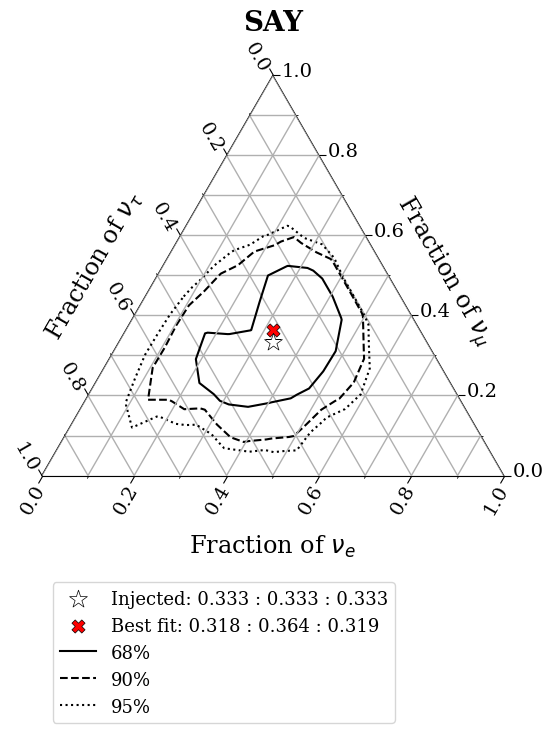

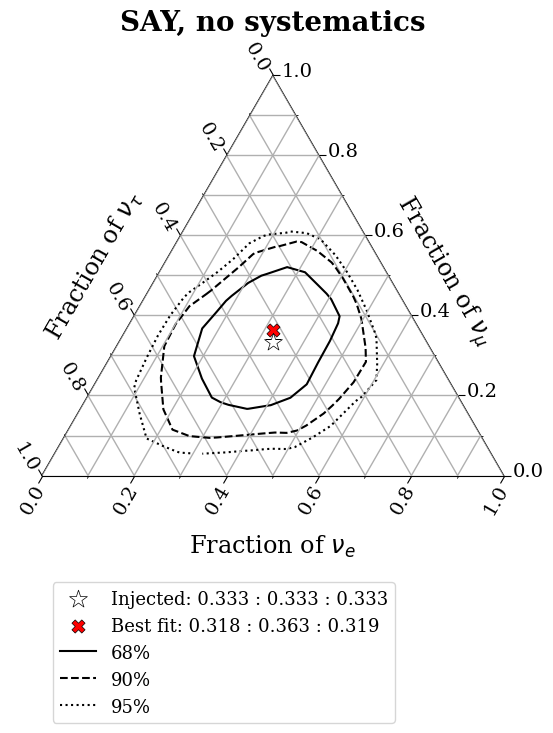

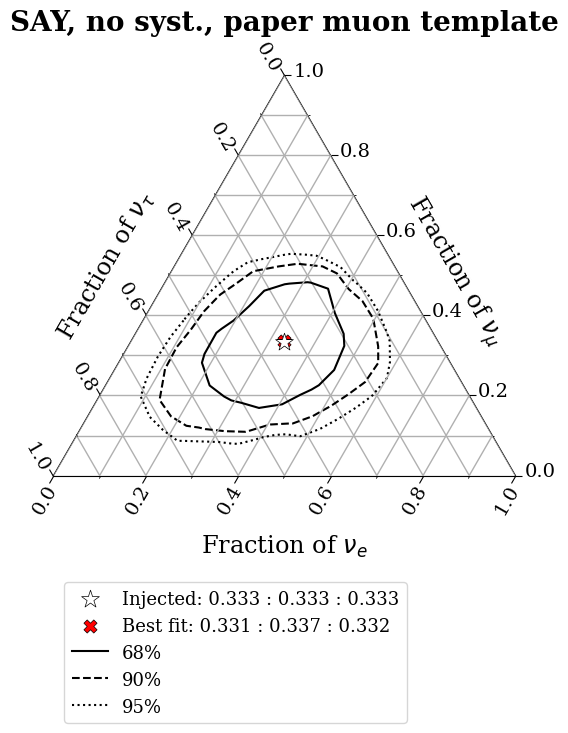

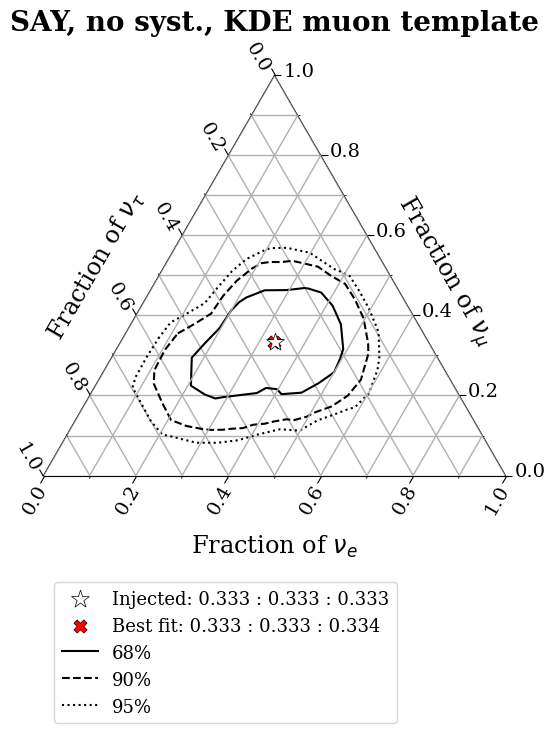

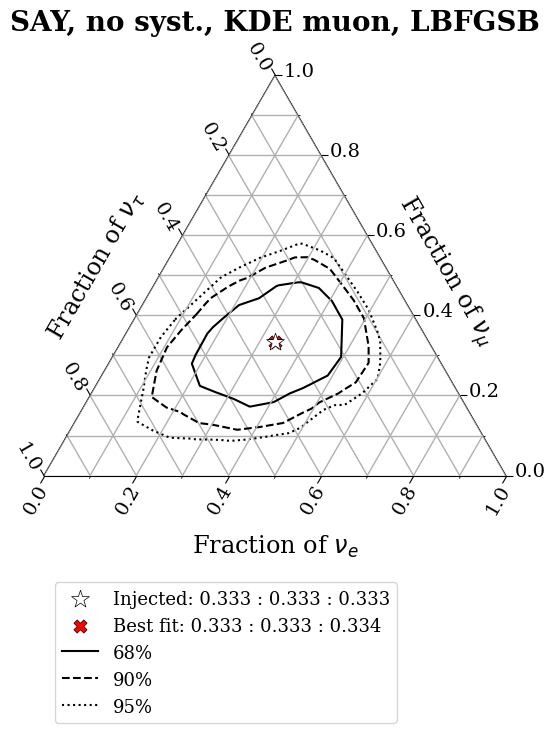

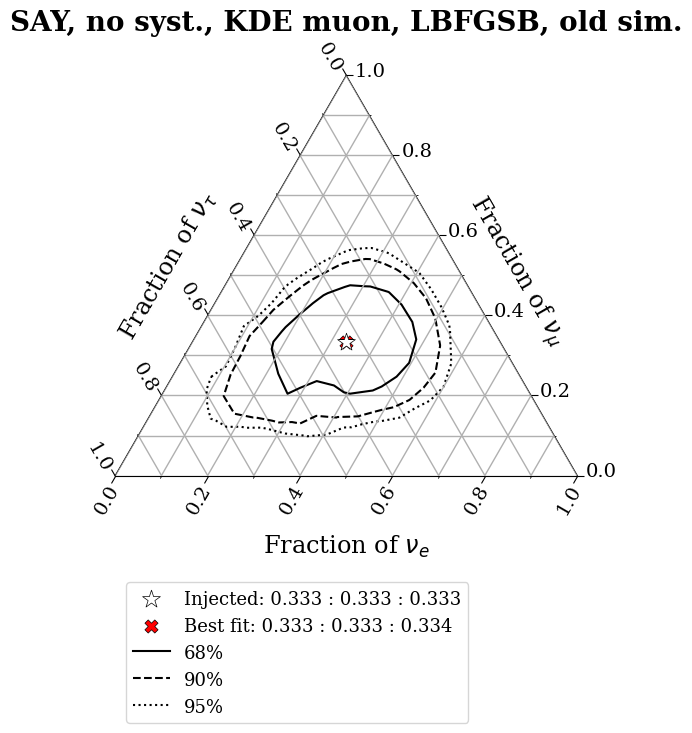

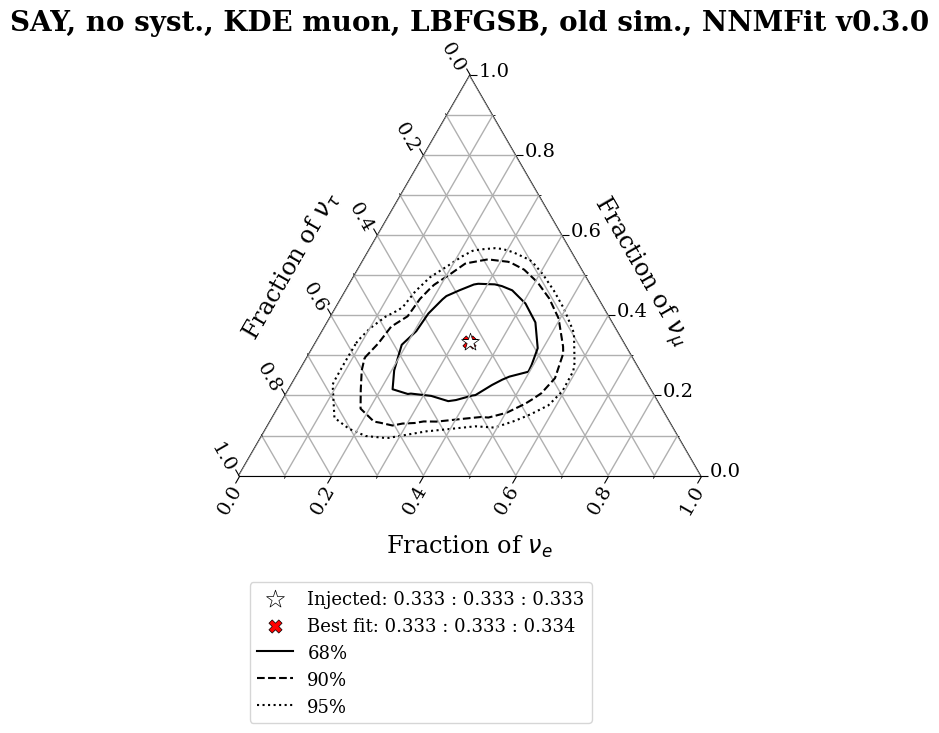

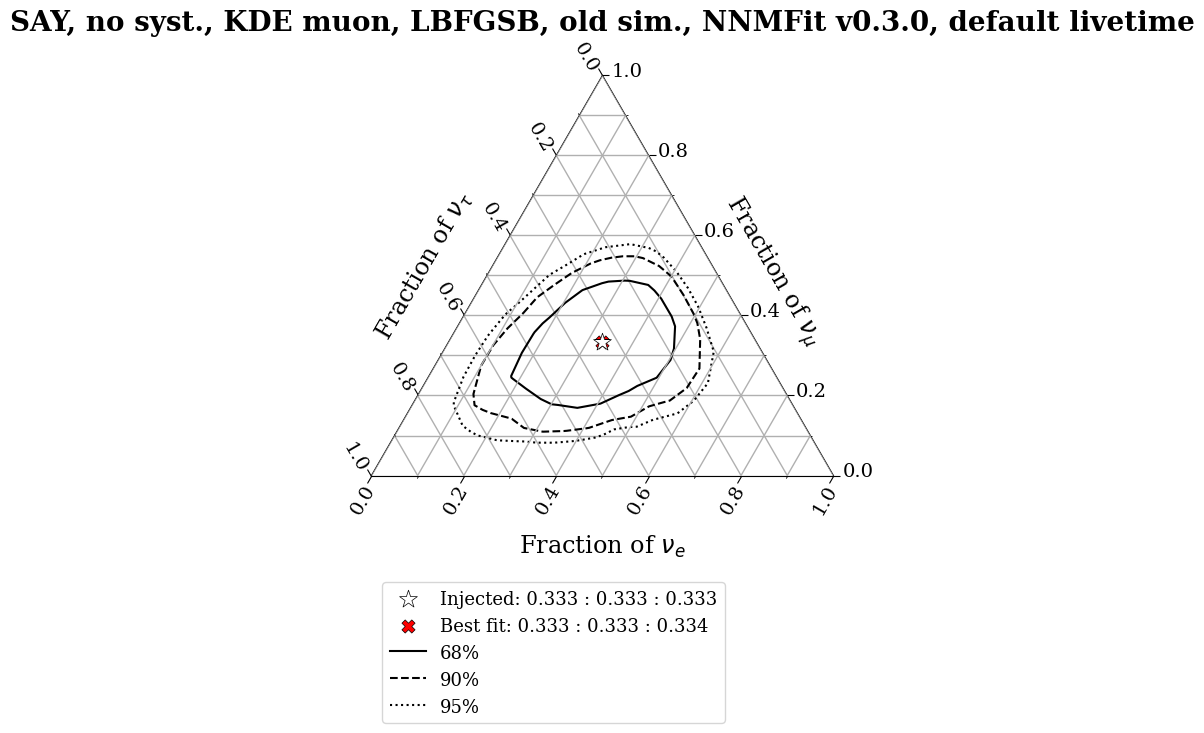

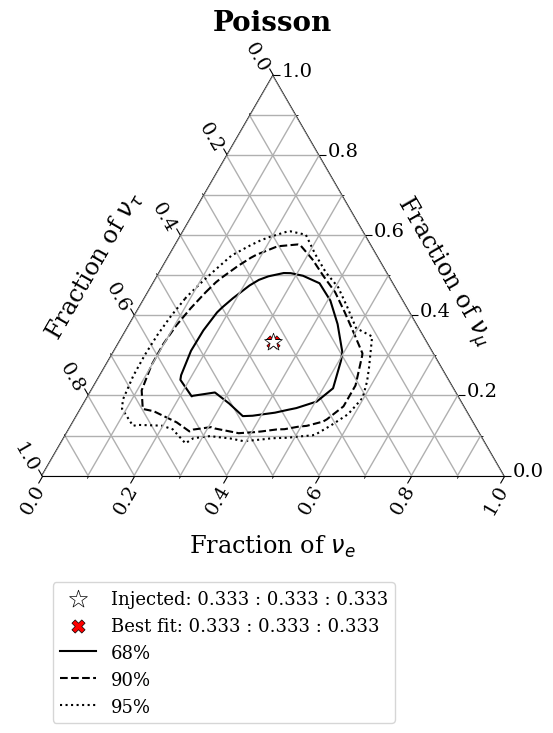

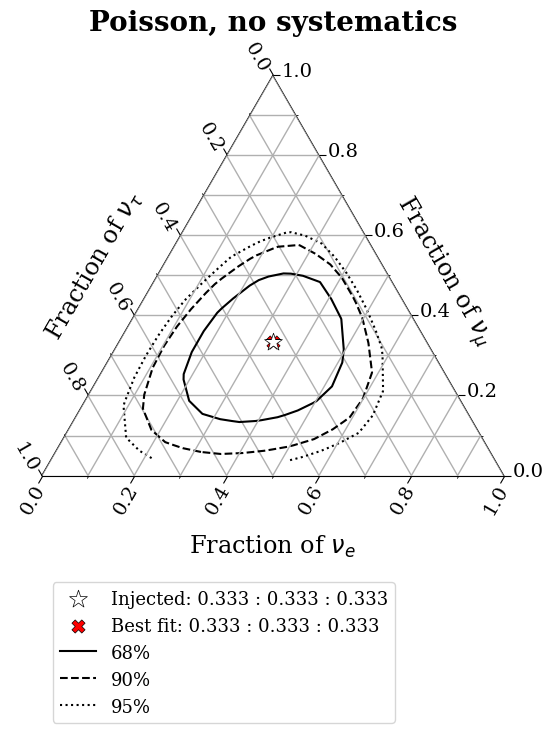

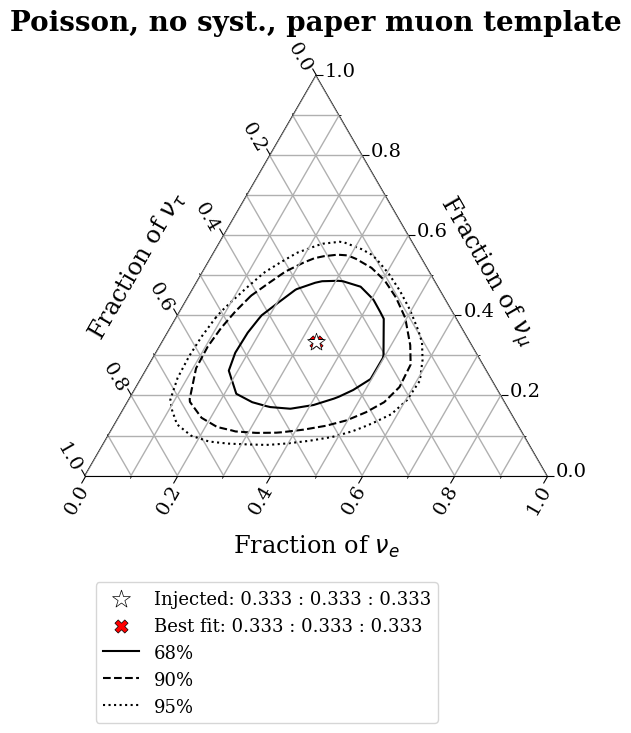

In [9]:
levels = ["68%", "90%", "95%"]
ts_values = [ts_dict[l] for l in levels]

def scatter_point(tax, params, **kwargs):
    fr = flavor_fractions(params)
    kwargs.setdefault("zorder", 10)
    return tax.ca.scatter([fr["f_tau"]], [fr["f_e"]], edgecolor="k", lw=0.5, **kwargs)

def composition(params):
    fr = flavor_fractions(params)
    return f"{fr['f_e']:.3f} : {fr['f_mu']:.3f} : {fr['f_tau']:.3f}"

def plot_closure_triangle(data, name, injected, bestfit, savepath=None):
    fig = plt.figure(figsize=(7,6))
    tax = flavor_triangle()

    C = tax.ca.contour(data[name]["ftau_grid"], data[name]["fe_grid"], data[name]["ts_grid"],
                       ts_values, linestyles=linestyles[:len(levels)], linewidths=1.5, colors=colours[0])

    lh, ll = [], []
    lh.append(scatter_point(tax, injected, marker="*", facecolor="white", s=180, zorder=11))
    ll.append(f"Injected: {composition(injected)}")
    lh.append(scatter_point(tax, bestfit, marker="X", facecolor="red", s=90))
    ll.append(f"Best fit: {composition(bestfit)}")
    for ls, level in zip(linestyles, levels):
        lh.append(Line2D([], [], color=colours[0], linestyle=ls))
        ll.append(level)
    fig.legend(lh, ll, bbox_to_anchor=(0.7, 0.05), prop=font_legend)

    plt.title(labels[name], y=1.08, fontdict=font_title)
    if savepath:
        plt.savefig(savepath, bbox_inches="tight")
    plt.show()

for name in scan_dir_dict:
    plot_closure_triangle(data, name, injected[name], bestfits[name],
                          savepath=f"{plotting_path}/asimov_closure_{name}.png")

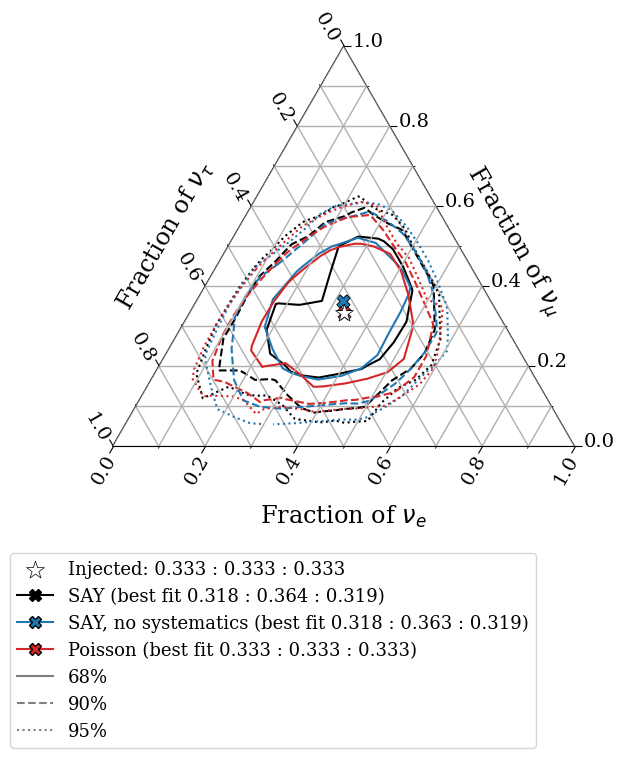

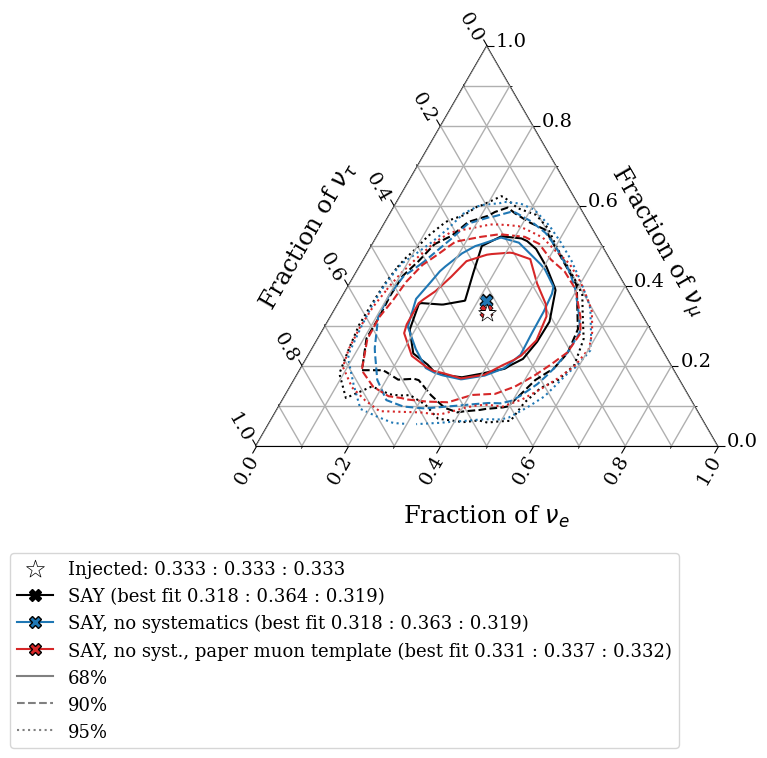

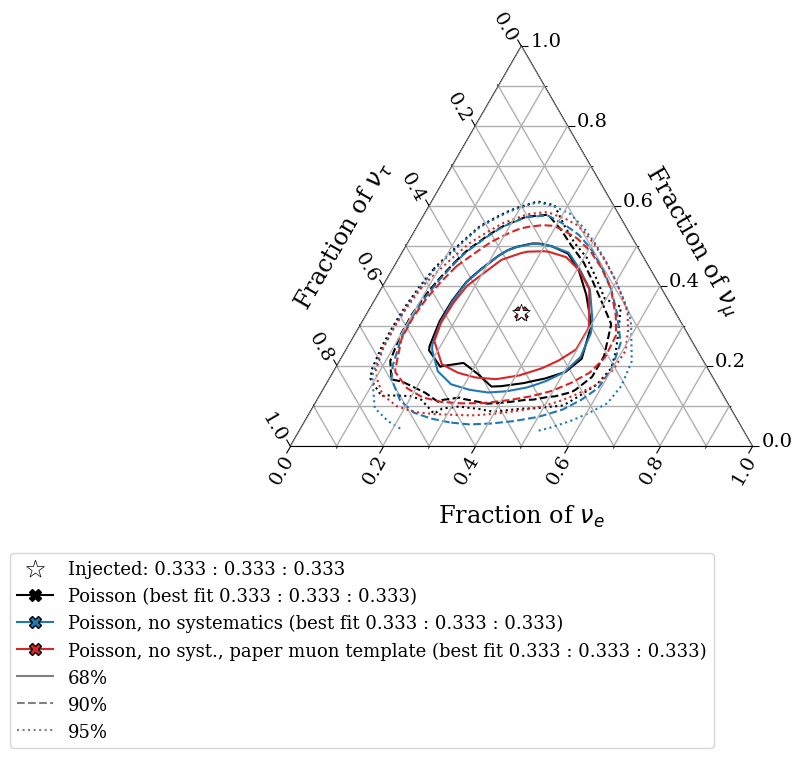

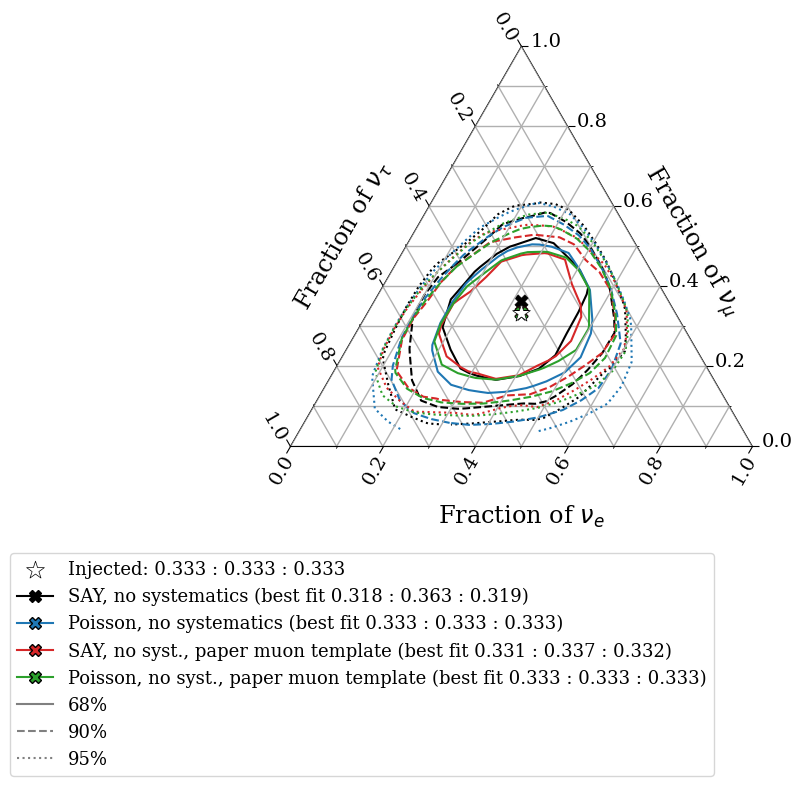

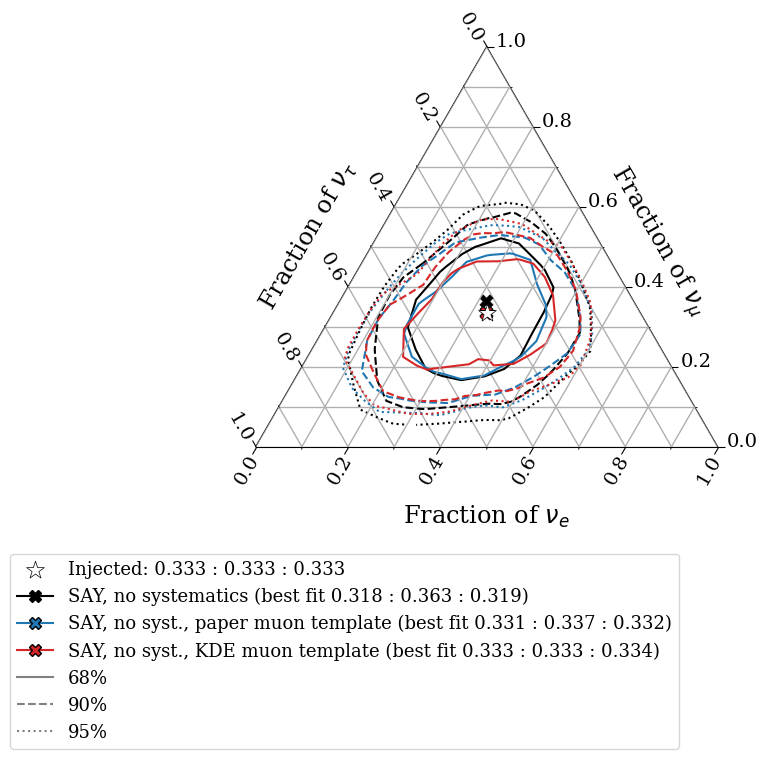

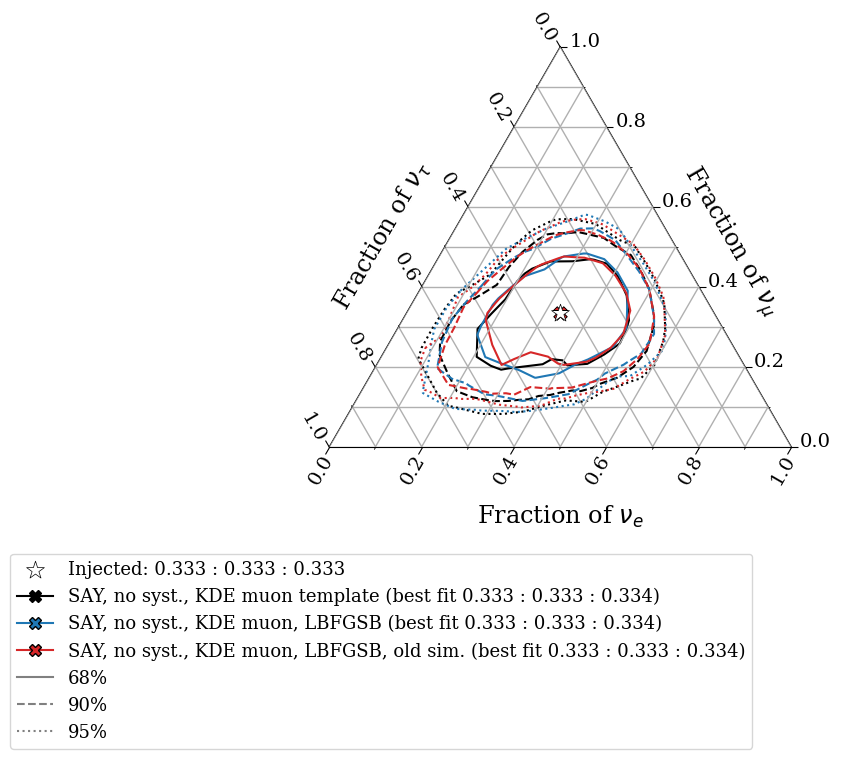

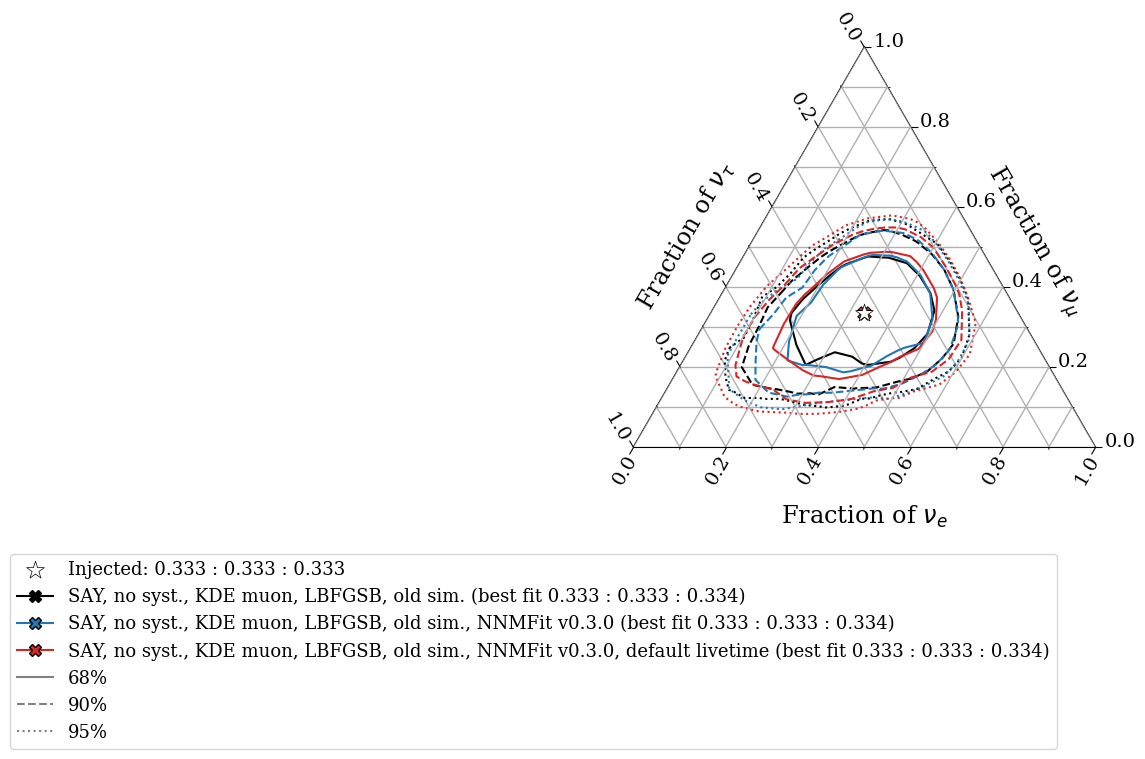

In [10]:
def plot_compare(names, savepath):
    fig = plt.figure(figsize=(7,6))
    tax = flavor_triangle()

    lh, ll = [], []
    lh.append(scatter_point(tax, injected[names[0]], marker="*", facecolor="white", s=180, zorder=11))
    ll.append(f"Injected: {composition(injected[names[0]])}")

    for i, name in enumerate(names):
        tax.ca.contour(data[name]["ftau_grid"], data[name]["fe_grid"], data[name]["ts_grid"],
                       ts_values, linestyles=linestyles[:len(levels)], linewidths=1.5, colors=colours[i])
        scatter_point(tax, bestfits[name], marker="X", facecolor=colours[i], s=90)
        lh.append(Line2D([], [], color=colours[i], marker="X", markeredgecolor="k", markersize=8))
        ll.append(f"{labels[name]} (best fit {composition(bestfits[name])})")

    for ls, level in zip(linestyles, levels):
        lh.append(Line2D([], [], color="grey", linestyle=ls))
        ll.append(level)
    fig.legend(lh, ll, bbox_to_anchor=(0.8, 0.05), prop=font_legend)

    plt.savefig(savepath, bbox_inches="tight")
    plt.show()

compare_groups = {
    "compare":         ["SAY", "SAY_nosyst", "Poisson"],
    "compare_SAY":     ["SAY", "SAY_nosyst", "SAY_nosyst_muonconv"],
    "compare_Poisson": ["Poisson", "Poisson_nosyst", "Poisson_nosyst_muonconv"],
    "compare_nosyst":  ["SAY_nosyst", "Poisson_nosyst", "SAY_nosyst_muonconv", "Poisson_nosyst_muonconv"],
    # SAY without systematics: muon template, then minimizer and simulation
    "compare_SAY_muon_template": ["SAY_nosyst", "SAY_nosyst_muonconv", "SAY_nosyst_muonconvneha"],
    "compare_SAY_minimizer_sim": ["SAY_nosyst_muonconvneha", "SAY_nosyst_muonconvneha_LBFGSB", "SAY_nosyst_muonconvneha_LBFGSB_oldsim"],
    "compare_SAY_nnmfit_livetime": ["SAY_nosyst_muonconvneha_LBFGSB_oldsim", "SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm",
                                    "SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm_oldlive"],
}
for group, names in compare_groups.items():
    plot_compare(names, f"{plotting_path}/asimov_closure_{group}.png")


## Comparison with the earlier benchmark scan
`SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm_oldlive` should reproduce the earlier Asimov benchmark
`dag_scans/flavor_globalfit/hese/SAY/hese_HESEBestfit_SPL_noinel_nosyst` (from `dag_scans/flavor_globalfit/create_dag_hese.sh`).
Both use the same command: `asimov/SAY/hese/hese_HESEBestfit_SPL.yaml`, `main.cfg`, the NNMFit v0.3.0 venv,
`NoSystematics_hese.cfg`, the old `..._length_10_fluxlessweight.cfg` datasets, the same binning, no livetime override,
`astro_SPL_no_inel.yaml`, the non-paper KDE muon template and the same custom scan points; only `n_bestfit 10` and `scan_memory` differ
(the reference has a single freefit), both use the plain LBFGSB minimizer.

Differences in `Fit_Configuration.yaml` (`main.cfg` changed in the meantime), none of which should affect this fit:
- the reference still defines the `inel_scale` parameter, unused with `astro_SPL_no_inel.yaml`;
- the reference has an empty `data` path (not used for an Asimov fit);
- the muon norm of the cascade globalfit template is renamed and the prior width of the track globalfit `muon_norm` differs,
  both globalfit components are skipped for the HESE detector configs;
- different SnowStorm gradient blocks are defined, both fits run with `NoSystematics_hese.cfg`.

In [11]:
reference_name = "reference_noinel_nosyst"
reference_dir = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/SAY/hese_HESEBestfit_SPL_noinel_nosyst"
new_name = "SAY_nosyst_muonconvneha_LBFGSB_oldsim_oldnnm_oldlive"

labels[reference_name] = "earlier SAY, hese_HESEBestfit_SPL"
scan_dict[reference_name], data[reference_name], bestfits[reference_name] = load_triangle_scan(
    reference_dir, N_grid=N_grid, drop_unsuccessful=drop_unsuccessful, drop_unsuccessful_points=drop_unsuccessful)
injected[reference_name] = get_injected(reference_dir)

for name in [reference_name, new_name]:
    print(f"{labels[name]}: freefit llh = {bestfits[name]['llh']:.4f}, {data[name]['n_converged']} converged, {len(data[name]['ts'])} used scan points")

removed stuff
earlier SAY, hese_HESEBestfit_SPL: freefit llh = 134.3636, 79 successful scan points
SAY, no syst., KDE muon, LBFGSB, old sim., NNMFit v0.3.0, default livetime: freefit llh = 134.3638, 82 successful scan points


In [12]:
# best fit of both scans for all parameters they have in common
rows = {}
for parameter in signal_parameters + sorted(p for p in injected[new_name] if p not in signal_parameters):
    if parameter in bestfits[reference_name] and parameter in bestfits[new_name]:
        rows[parameter] = {"injected": injected[new_name][parameter],
                           "reference": bestfits[reference_name][parameter], "new": bestfits[new_name][parameter]}
for frac in ["f_e", "f_mu", "f_tau"]:
    rows[frac] = {"injected": flavor_fractions(injected[new_name])[frac],
                  "reference": flavor_fractions(bestfits[reference_name])[frac], "new": flavor_fractions(bestfits[new_name])[frac]}
rows["llh"] = {"injected": np.nan, "reference": bestfits[reference_name]["llh"], "new": bestfits[new_name]["llh"]}
df_reference = pd.DataFrame(rows).T
df_reference["new - reference"] = df_reference["new"] - df_reference["reference"]
with pd.option_context("display.float_format", "{:.5f}".format):
    display(df_reference)

,injected,reference,new,new - reference
astro_norm,2.12330,2.12415,2.12377,-0.00038
gamma_astro,2.87000,2.87333,2.87330,-0.00003
astro_nue_ratio,1.00000,0.99874,0.99888,0.00013
astro_nutau_ratio,1.00000,1.00118,1.00133,0.00015
CR_grad,0.00000,0.00727,0.00748,0.00021
barr_h,0.00000,-0.00007,-0.00008,-0.00000
barr_w,0.00000,-0.00077,-0.00079,-0.00002
barr_y,0.00000,-0.00216,-0.00222,-0.00007
barr_z,0.00000,-0.00106,-0.00109,-0.00003
conv_norm,1.00000,0.99879,0.99875,-0.00004


common successful scan points: 60
TS(new) - TS(reference): max |diff| = 0.1641, mean |diff| = 0.03403, mean diff = +0.03403


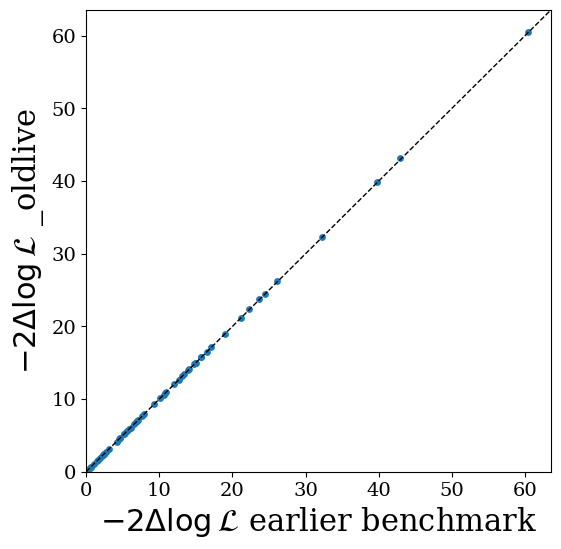

In [13]:
# profile point by point: scan points present in both scans
def scan_points(name):
    return pd.DataFrame({"ftau": np.round(data[name]["ftau"], 6), "fe": np.round(data[name]["fe"], 6), "ts": data[name]["ts"]})

common = scan_points(reference_name).merge(scan_points(new_name), on=["ftau", "fe"], suffixes=("_reference", "_new"))
delta = common["ts_new"] - common["ts_reference"]
print(f"common scan points: {len(common)}")
print(f"TS(new) - TS(reference): max |diff| = {np.abs(delta).max():.4g}, mean |diff| = {np.abs(delta).mean():.4g}, mean diff = {delta.mean():+.4g}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(common["ts_reference"], common["ts_new"], s=15, color="C0")
lim = [0, max(common["ts_reference"].max(), common["ts_new"].max()) * 1.05]
ax.plot(lim, lim, color="black", linestyle="--", linewidth=1)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel(r"$-2\Delta\log\mathcal{L}$ earlier benchmark", fontdict=font_axis_label)
ax.set_ylabel(r"$-2\Delta\log\mathcal{L}$ " + "_oldlive", fontdict=font_axis_label)
plt.savefig(f"{plotting_path}/asimov_closure_reference_ts_scatter.png", bbox_inches="tight")
plt.show()

/data/user/tvaneede/utils/Ternary.py:74: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.xaxis.grid(*args, **kwargs)


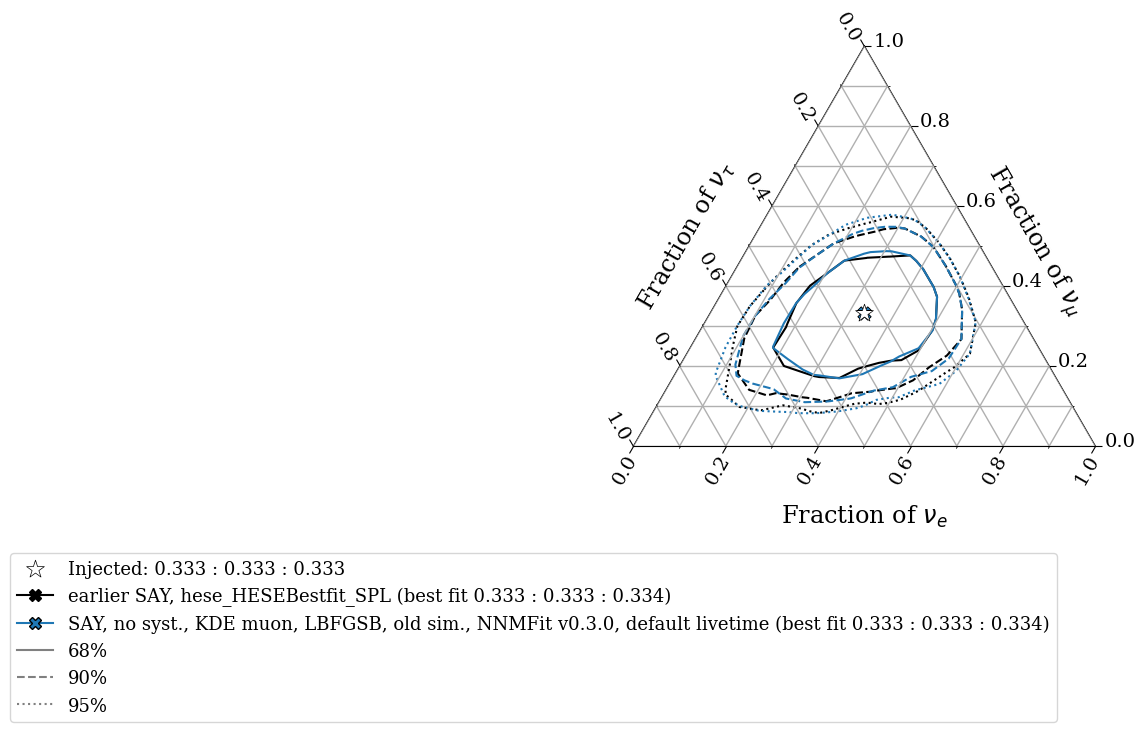

In [14]:
plot_compare([reference_name, new_name], f"{plotting_path}/asimov_closure_compare_reference.png")

**Outcome:** `_oldlive` reproduces the earlier benchmark. The best fits agree to better than 0.002 in every parameter
(astro_norm 2.1238 vs 2.1242, muongun_norm 0.9787 vs 0.9772, identical 0.333 : 0.333 : 0.334 composition) and the freefit llh to 0.0003
(134.3638 vs 134.3636). On the 60 scan points that converged in both scans the profile agrees within |ΔTS| ≤ 0.16 (mean 0.03,
the new scan is systematically slightly higher, i.e. the scan-point minimizations differ a little). The small differences in the
contours come mostly from the different sets of converged scan points (79 vs 82 of 103) entering the interpolation.

## Earlier benchmark scans: SAY vs Poisson
Asimov flavor scans from `dag_scans/flavor_globalfit/create_dag_hese.sh` (NNMFit v0.3.0, no systematics, no inelasticity, single freefit),
for the injected hese_SPL point (astro_norm 1.8, γ 2.52) and the hese_HESEBestfit_SPL point (astro_norm 2.1233, γ 2.87), both 1:1:1.
The SAY hese_HESEBestfit_SPL scan is the benchmark reproduced above (`reference_noinel_nosyst`).

In [15]:
old_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese"
old_scan_dirs = {
    "old_SAY_SPL"             : f"{old_path}/SAY/hese_SPL_noinel_nosyst",
    "old_Poisson_SPL"         : f"{old_path}/Poisson/hese_SPL_noinel_nosyst",
    "old_Poisson_HESEBestfit" : f"{old_path}/Poisson/hese_HESEBestfit_SPL_noinel_nosyst",
}
labels.update({
    "old_SAY_SPL"             : "earlier SAY, hese_SPL",
    "old_Poisson_SPL"         : "earlier Poisson, hese_SPL",
    "old_Poisson_HESEBestfit" : "earlier Poisson, hese_HESEBestfit_SPL",
})

for name, scan_dir in old_scan_dirs.items():
    scan_dict[name], data[name], bestfits[name] = load_triangle_scan(
        scan_dir, N_grid=N_grid, drop_unsuccessful=drop_unsuccessful, drop_unsuccessful_points=drop_unsuccessful)
    injected[name] = get_injected(scan_dir)

old_names = ["old_SAY_SPL", "old_Poisson_SPL", reference_name, "old_Poisson_HESEBestfit"]
for name in old_names:
    print(f"{labels[name]}: {data[name]['n_converged']} converged, {len(data[name]['ts'])} used scan points, freefit llh = {bestfits[name]['llh']:.4f}")

removed stuff
removed stuff
removed stuff
earlier SAY, hese_SPL: 73 successful scan points, freefit llh = 159.4848
earlier Poisson, hese_SPL: 103 successful scan points, freefit llh = 0.0000
earlier SAY, hese_HESEBestfit_SPL: 79 successful scan points, freefit llh = 134.3636
earlier Poisson, hese_HESEBestfit_SPL: 103 successful scan points, freefit llh = 0.0000


In [16]:
# best fit vs injected of the earlier benchmark scans
old_parameters = signal_parameters + ["muongun_norm", "conv_norm"]
columns = {}
for name in old_names:
    inj, bf = injected[name], bestfits[name]
    columns[(labels[name], "injected")] = {**{p: inj[p] for p in old_parameters}, **flavor_fractions(inj), "llh": np.nan}
    columns[(labels[name], "bestfit")] = {**{p: bf[p] for p in old_parameters}, **flavor_fractions(bf), "llh": bf["llh"]}
df_old = pd.DataFrame(columns)
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250, "display.max_columns", 20):
    display(df_old)

earlier SAY, hese_SPL          earlier Poisson, hese_SPL         earlier SAY, hese_HESEBestfit_SPL          earlier Poisson, hese_HESEBestfit_SPL        
                               injected  bestfit                  injected bestfit                          injected  bestfit                              injected bestfit
astro_norm                       1.8000   1.8066                    1.8000  1.8000                            2.1233   2.1241                                2.1233  2.1233
gamma_astro                      2.5200   2.5248                    2.5200  2.5200                            2.8700   2.8733                                2.8700  2.8700
astro_nue_ratio                  1.0000   0.9940                    1.0000  1.0000                            1.0000   0.9987                                1.0000  1.0000
astro_nutau_ratio                1.0000   1.0038                    1.0000  1.0000                            1.0000   1.0012                                1.0000  1.0000
muongun_norm                     1.0000   0.9783                    1.0000  1.0000                            1.0000   0.9772                                1.0000  1.0000
conv_norm                        1.0000   0.9987                    1.0000  1.0000                            1.0000   0.9988                                1.0000  1.0000
f_e                              0.3333   0.3316                    0.3333  0.3333                            0.3333   0.3329                                0.3333  0.3333
f_mu                             0.3333   0.3336                    0.3333  0.3333                            0.3333   0.3333                                0.3333  0.3333
f_tau                            0.3333   0.3348                    0.3333  0.3333                            0.3333   0.3337                                0.3333  0.3333
llh                                 NaN 159.4848                       NaN  0.0000                               NaN 134.3636                                   NaN  0.0000

/data/user/tvaneede/utils/Ternary.py:74: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.xaxis.grid(*args, **kwargs)


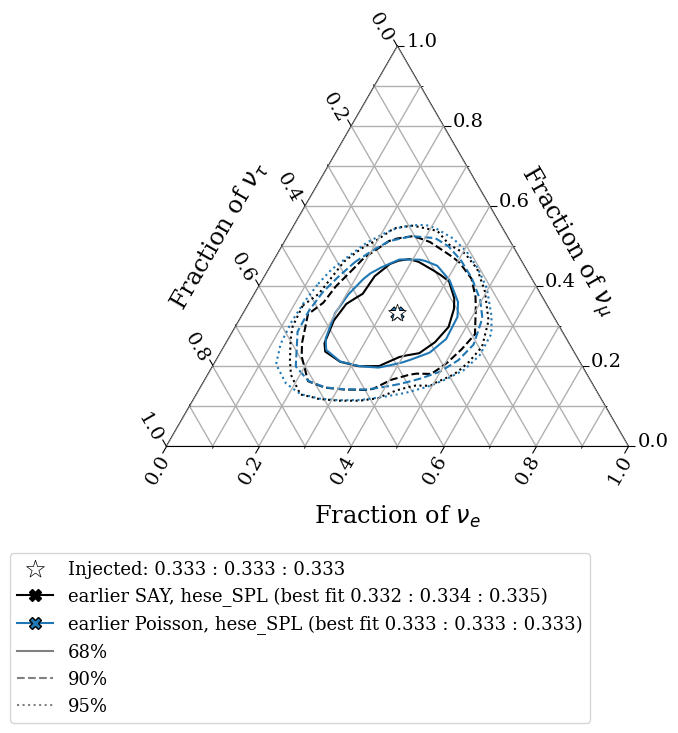

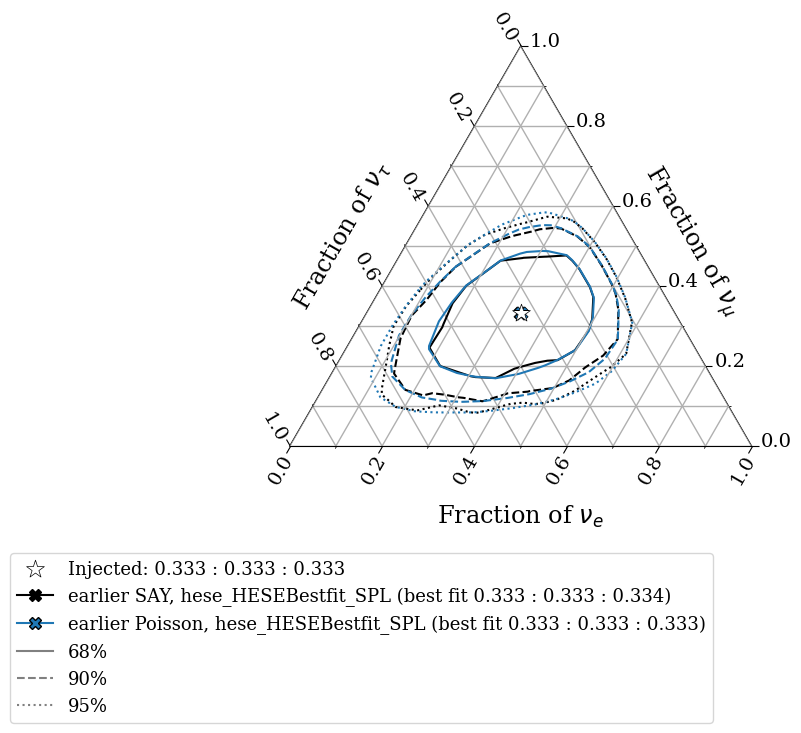

In [17]:
plot_compare(["old_SAY_SPL", "old_Poisson_SPL"], f"{plotting_path}/asimov_closure_old_SPL_SAY_vs_Poisson.png")
plot_compare([reference_name, "old_Poisson_HESEBestfit"], f"{plotting_path}/asimov_closure_old_HESEBestfit_SAY_vs_Poisson.png")

## Failed scan fits
`FlavourScansPlotting.get_contour_points` always calls `get_scan_xydllh(..., drop_unsuccessful=True)`, so the
`drop_unsuccessful` of the `ScanHandler` has no effect there. With NNMFit v0.3.0 (kernel of
`presentations/2026-03-12_diffuse_update.ipynb`) this did not matter, since `result_handlers.py` hardcodes `success = 1`;
from v0.5.0 on the real minimizer flag is read and failed fits (`ABNORMAL_TERMINATION_IN_LNSRCH`) are removed, e.g. 30 of 103
points of the earlier SAY hese_SPL scan, which makes its contours jagged. This notebook uses `load_triangle_scan` with
`drop_unsuccessful_points=drop_unsuccessful` (= False), so all scan points are used above. Below: the earlier SAY hese_SPL
scan with only converged points vs all points, and whether the failed points lie on the Poisson profile.

In [ ]:
old_SAY_dir = old_scan_dirs["old_SAY_SPL"]
_, data["old_SAY_SPL_converged"], bestfits["old_SAY_SPL_converged"] = load_triangle_scan(
    old_SAY_dir, N_grid=N_grid, drop_unsuccessful=drop_unsuccessful, drop_unsuccessful_points=True)
injected["old_SAY_SPL_converged"] = injected["old_SAY_SPL"]
labels["old_SAY_SPL_converged"] = "earlier SAY, hese_SPL, converged points only"
labels["old_SAY_SPL"] = "earlier SAY, hese_SPL, all points"
print(f"converged: {len(data['old_SAY_SPL_converged']['ts'])}, all: {len(data['old_SAY_SPL']['ts'])}")

plot_compare(["old_SAY_SPL_converged", "old_SAY_SPL"], f"{plotting_path}/asimov_closure_old_SPL_SAY_converged_vs_all.png")

In [ ]:
# TS of the failed SAY points vs Poisson at the same scan point (earlier benchmarks: SAY ~ Poisson)
def scan_points(name):
    return pd.DataFrame({"ftau": np.round(data[name]["ftau"], 6), "fe": np.round(data[name]["fe"], 6), "ts": data[name]["ts"]})

say_all = scan_points("old_SAY_SPL").merge(scan_points("old_SAY_SPL_converged"), on=["ftau", "fe"], how="left",
                                           suffixes=("", "_conv"), indicator=True)
say_all["failed"] = say_all["_merge"] == "left_only"
cmp = say_all.merge(scan_points("old_Poisson_SPL"), on=["ftau", "fe"], suffixes=("_SAY", "_Poisson"))
for flag, group in cmp.groupby("failed"):
    d = group["ts_SAY"] - group["ts_Poisson"]
    print(f"{'failed' if flag else 'converged'} SAY fits ({len(group)}): TS(SAY) - TS(Poisson): "
          f"max |diff| = {np.abs(d).max():.3g}, mean diff = {d.mean():+.3g}")

fig, ax = plt.subplots(figsize=(6, 6))
for flag, color, label in [(False, "C0", "converged"), (True, "C3", "failed (ABNORMAL_TERMINATION_IN_LNSRCH)")]:
    group = cmp[cmp["failed"] == flag]
    ax.scatter(group["ts_Poisson"], group["ts_SAY"], s=15, color=color, label=label)
lim = [0, max(cmp["ts_Poisson"].max(), cmp["ts_SAY"].max()) * 1.05]
ax.plot(lim, lim, color="black", linestyle="--", linewidth=1)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel(r"$-2\Delta\log\mathcal{L}$ Poisson", fontdict=font_axis_label)
ax.set_ylabel(r"$-2\Delta\log\mathcal{L}$ SAY", fontdict=font_axis_label)
ax.legend(prop=font_legend)
plt.savefig(f"{plotting_path}/asimov_closure_old_SPL_failed_points.png", bbox_inches="tight")
plt.show()

**Outcome:** with all scan points the earlier SAY and Poisson hese_SPL contours coincide, reproducing
`compare_likelihood_hese.png` from the presentation. The 30 failed SAY fits lie on the Poisson profile just as well as the 73
converged ones (|TS(SAY) − TS(Poisson)| ≤ 0.83 vs ≤ 0.67, mean −0.04 vs −0.02), so the `ABNORMAL_TERMINATION_IN_LNSRCH` flag
marks line-search terminations at a valid minimum here, and dropping these points only removes information from the contours.